In [1]:
# Cell: imports and helpers
import json
import os
import re
import csv
from collections import Counter, defaultdict
from typing import List, Dict, Any, Tuple

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix
from plagiarism_detectors import detect_embedding, detect_llm, detect_rag, detect_hybrid_rag



# ensure results folder
os.makedirs("results", exist_ok=True)

# Helper: normalize LLM responses to binary decision 1=plagiarized,0=original, None=unknown/error
def llm_text_to_label(text: str) -> int:
    if text is None:
        return None
    t = text.strip().lower()
    # common positive forms
    if re.search(r'\b(plagiariz|yes|true|copied|taken)\b', t):
        return 1
    if re.search(r'\b(original|no\b|not plagiar|no evidence|unique|different)\b', t):
        return 0
    # fallback: look for explicit 'yes' or 'no' lines
    lines = [l.strip().lower() for l in t.splitlines() if l.strip()]
    if lines:
        first = lines[0]
        if 'yes' == first or 'plagiarized' in first:
            return 1
        if 'no' == first or 'original' in first:
            return 0
    # if uncertain, return None
    return None

# Unified runner wrapper for each method -> returns predicted label 1/0/None, plus raw result
def run_detector(detector_fn, test_code: str, method_name: str, **kwargs) -> Tuple[int, Any]:
    """
    detector_fn: callable that returns either dict or string
    returns: (pred_label (1/0/None), raw_result)
    """
    try:
        res = detector_fn(test_code, **kwargs)
    except Exception as e:
        # don't crash whole evaluation if a call fails for some input
        print(f"[Error] {method_name} failed on a case: {e}")
        return None, {"error": str(e)}
    # normalize based on return type
    # detector may return dict with 'is_plagiarized' (boolean) or 'llm_response' (str)
    if isinstance(res, dict):
        if "is_plagiarized" in res:
            try:
                return (1 if res["is_plagiarized"] else 0), res
            except Exception:
                return None, res
        if "llm_response" in res:
            return llm_text_to_label(res["llm_response"]), res
        # fallback: check top-level text fields
        for k in ("answer","response","result"):
            if k in res and isinstance(res[k], str):
                return llm_text_to_label(res[k]), res
        # fallback unknown
        return None, res
    elif isinstance(res, str):
        return llm_text_to_label(res), res
    else:
        return None, res


c:\Users\user\Desktop\applied_llm_homework\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded 148 file-level code entries.
Loaded 148 files for direct LLM analysis.
BM25 index built successfully — ready for hybrid RAG


In [2]:
# Cell: load test cases
with open("data/test_dataset.json", "r", encoding="utf-8") as f:
    dataset_raw = json.load(f)

test_cases = dataset_raw.get("test_cases") or dataset_raw.get("test_cases", [])
print(f"Loaded {len(test_cases)} test cases from data/test_cases.json")
# quick check of metadata if present
print("Metadata:", dataset_raw.get("metadata", {}))


Loaded 35 test cases from data/test_cases.json
Metadata: {'total_cases': 35, 'plagiarized_cases': 22, 'non_plagiarized_cases': 13, 'programming_language': 'python', 'transformation_types': {'variable_renaming': 9, 'structure_reordering': 3, 'minor_refactoring': 5, 'comment_removal': 2, 'combined_transformations': 3}}


In [3]:
# Cell: generic evaluation function for a given detector
def evaluate_on_dataset(detector_fn, method_name: str, detector_kwargs=None):
    detector_kwargs = detector_kwargs or {}
    y_true = []
    y_pred = []
    raw_results = []

    for case in test_cases:
        code = case["query_code"]
        true_label = 1 if case["label"] in ("plagiarized","Plagiarized","PLAGIARIZED") else 0
        pred_label, raw = run_detector(detector_fn, code, method_name, **detector_kwargs)
        # treat None predictions as 0 (conservative) OR keep as None — we'll handle below
        y_true.append(true_label)
        y_pred.append(pred_label if pred_label is not None else 0)  # choose conservative mapping for metrics
        raw_results.append({"id": case["id"], "true": true_label, "pred": pred_label, "raw": raw, "meta": case})

    # compute metrics (using our conservative mapping for None->0)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    summary = {
        "method": method_name,
        "precision": precision,
        "recall": recall,
        "accuracy": accuracy,
        "f1": f1,
        "n_cases": len(test_cases),
        "raw_results": raw_results
    }
    return summary


In [4]:
# Cell: evaluate all four methods
results_all = {}
# 1) Pure Embedding
print("Evaluating: detect_embedding (embedding only)...")
results_all["embedding"] = evaluate_on_dataset(detector_fn=detect_embedding, method_name="embedding", detector_kwargs={"top_k":5, "threshold":0.7})

# 2) Direct LLM (use small max_files to keep costs reasonable)
print("Evaluating: detect_llm (direct LLM)...")
results_all["llm"] = evaluate_on_dataset(detector_fn=detect_llm, method_name="llm", detector_kwargs={"max_files":50})

Evaluating: detect_embedding (embedding only)...
Evaluating: detect_llm (direct LLM)...


In [5]:


# 3) Standard RAG
print("Evaluating: detect_rag (RAG)...")
results_all["rag"] = evaluate_on_dataset(detector_fn=detect_rag, method_name="rag", detector_kwargs={"top_k":5, "threshold":0.7})

# 4) Hybrid RAG
print("Evaluating: detect_hybrid_rag (Hybrid RAG)...")
results_all["hybrid_rag"] = evaluate_on_dataset(detector_fn=detect_hybrid_rag, method_name="hybrid_rag", detector_kwargs={"top_k_embeddings":5, "top_k_bm25":5, "weight_emb":0.6, "weight_bm25":0.4})

# Save summary metrics to JSON and CSV
with open("results/metrics_summary.json", "w", encoding="utf-8") as f:
    json.dump({k:{k2:results_all[k][k2] for k2 in ("precision","recall","accuracy","f1","n_cases")} for k in results_all}, f, indent=2)

# CSV
with open("results/metrics_summary.csv","w",newline="",encoding="utf-8") as csvfile:
    writer = csv.writer(csvfile)
    writer.writerow(["method","precision","recall","accuracy","f1","n_cases"])
    for m, s in results_all.items():
        writer.writerow([m, s["precision"], s["recall"], s["accuracy"], s["f1"], s["n_cases"]])

print("Saved summary metrics to results/metrics_summary.json and .csv")
results_all


Evaluating: detect_rag (RAG)...
Evaluating: detect_hybrid_rag (Hybrid RAG)...
Saved summary metrics to results/metrics_summary.json and .csv


{'embedding': {'method': 'embedding',
  'precision': 0.8,
  'recall': 0.8421052631578947,
  'accuracy': 0.8,
  'f1': 0.8205128205128205,
  'n_cases': 35,
  'raw_results': [{'id': 1,
    'true': 1,
    'pred': 1,
    'raw': {'is_plagiarized': True,
     'max_similarity': 0.7308100461959839,
     'top_matches': [{'index': 18,
       'similarity': 0.7308100461959839,
       'snippet': 'def backtrack(input_string: str, word_dict: set[str], start: int) -> bool: if start == len(input_string): return True for end in range(start + 1, len(input_string) + 1): if input_string[start:end] in word_dict and backtrack( input_string, word_dict, end ): return True return False def word_break(input_string: str, word_dict: set[str]) -> bool: return backtrack(input_string, word_dict, 0)'},
      {'index': 5,
       'similarity': 0.6250531673431396,
       'snippet': 'def is_valid( puzzle: list[list[str]], word: str, row: int, col: int, vertical: bool ) -> bool: for i in range(len(word)): if vertical: if ro

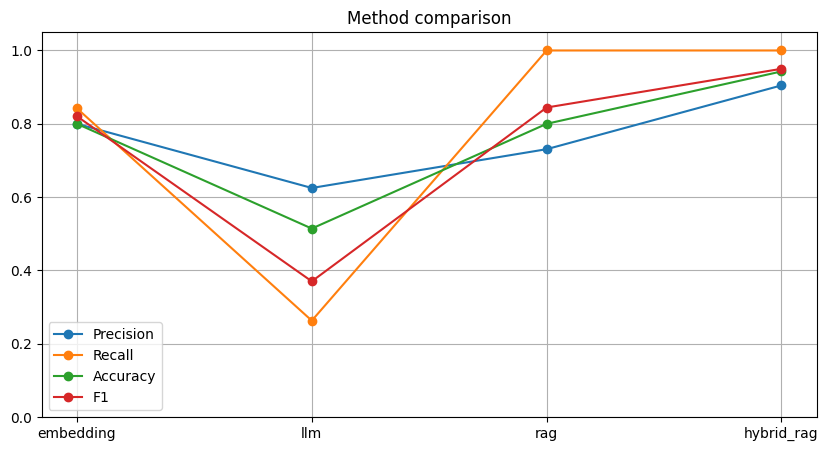

Saved results/method_comparison.png


In [6]:
# Cell: plot comparison chart
methods = list(results_all.keys())
prec = [results_all[m]["precision"] for m in methods]
rec = [results_all[m]["recall"] for m in methods]
acc = [results_all[m]["accuracy"] for m in methods]
f1 = [results_all[m]["f1"] for m in methods]

x = np.arange(len(methods))
plt.figure(figsize=(10,5))
plt.plot(methods, prec, marker='o', label='Precision')
plt.plot(methods, rec, marker='o', label='Recall')
plt.plot(methods, acc, marker='o', label='Accuracy')
plt.plot(methods, f1, marker='o', label='F1')
plt.ylim(0,1.05)
plt.title("Method comparison")
plt.legend()
plt.grid(True)
plt.savefig("results/method_comparison.png", bbox_inches='tight')
plt.show()
print("Saved results/method_comparison.png")


RAG ablation: top_k=1
RAG ablation: top_k=3
RAG ablation: top_k=4
RAG ablation: top_k=5
Saved results/rag_ablation.json


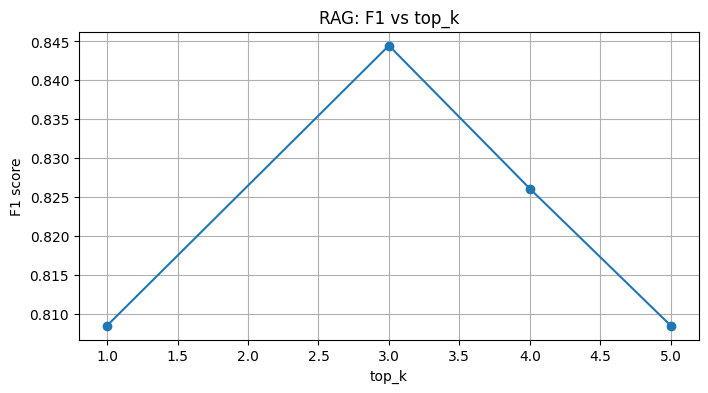

In [7]:
# Cell: ablation study for RAG varying k
k_values = [1,3,4,5]
rag_ablation = {}
for k in k_values:
    print(f"RAG ablation: top_k={k}")
    rag_ablation[k] = evaluate_on_dataset(detector_fn=detect_rag, method_name=f"rag_k_{k}", detector_kwargs={"top_k":k, "threshold":0.7})
# save
with open("results/rag_ablation.json","w",encoding="utf-8") as f:
    json.dump(rag_ablation, f, indent=2)
print("Saved results/rag_ablation.json")
# quick plot
plt.figure(figsize=(8,4))
plt.plot(k_values, [rag_ablation[k]["f1"] for k in k_values], marker='o')
plt.title("RAG: F1 vs top_k")
plt.xlabel("top_k")
plt.ylabel("F1 score")
plt.grid(True)
plt.savefig("results/rag_f1_vs_k.png", bbox_inches='tight')
plt.show()


Hybrid ablation: alpha=0.2
Hybrid ablation: alpha=0.4
Hybrid ablation: alpha=0.6
Hybrid ablation: alpha=0.8


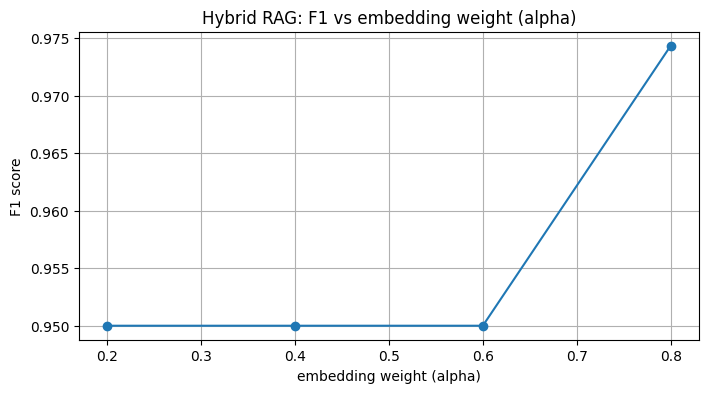

Saved hybrid ablation plots into results/


In [8]:
# Cell: ablation study for hybrid RAG varying alpha (weight for embedding)
alpha_values = [0.2,0.4,0.6,0.8]
hybrid_ablation = {}
for alpha in alpha_values:
    print(f"Hybrid ablation: alpha={alpha}")
    # we use weight_emb=alpha, weight_bm25=1-alpha
    hybrid_ablation[alpha] = evaluate_on_dataset(
        detector_fn=detect_hybrid_rag,
        method_name=f"hybrid_alpha_{alpha}",
        detector_kwargs={"top_k_embeddings":5,"top_k_bm25":5,"weight_emb":alpha,"weight_bm25":1-alpha}
    )

with open("results/hybrid_ablation.json","w",encoding="utf-8") as f:
    json.dump(hybrid_ablation, f, indent=2)

# quick plot
plt.figure(figsize=(8,4))
plt.plot(alpha_values, [hybrid_ablation[a]["f1"] for a in alpha_values], marker='o')
plt.title("Hybrid RAG: F1 vs embedding weight (alpha)")
plt.xlabel("embedding weight (alpha)")
plt.ylabel("F1 score")
plt.grid(True)
plt.savefig("results/hybrid_f1_vs_alpha.png", bbox_inches='tight')
plt.show()
print("Saved hybrid ablation plots into results/")


In [9]:
# Cell: failure analysis
def failure_analysis(raw_results):
    fp = []  # predicted plagiarized but true original
    fn = []  # predicted original but true plagiarized
    for row in raw_results:
        true = row["true"]
        pred = row["pred"] if row["pred"] is not None else 0
        meta = row["meta"]
        if true == 0 and pred == 1:
            fp.append(meta)
        if true == 1 and pred == 0:
            fn.append(meta)
    return fp, fn

analysis_summary = {}
for m, s in results_all.items():
    raw = s["raw_results"]
    fp, fn = failure_analysis(raw)
    # patterns by transformation type
    fp_types = Counter([c.get("transformation_type","unknown") for c in fp])
    fn_types = Counter([c.get("transformation_type","unknown") for c in fn])
    analysis_summary[m] = {
        "false_positives_count": len(fp),
        "false_negatives_count": len(fn),
        "fp_by_type": fp_types,
        "fn_by_type": fn_types,
        "fp_examples": fp[:3],
        "fn_examples": fn[:3]
    }

# save
with open("results/failure_analysis.json","w",encoding="utf-8") as f:
    # convert counters to dicts
    serial = {k: {**v, "fp_examples":analysis_summary[k]["fp_examples"], "fn_examples":analysis_summary[k]["fn_examples"]} for k,v in ((k, analysis_summary[k]["fp_by_type"]) for k in analysis_summary)}
    # simpler save:
    json.dump(analysis_summary, f, default=lambda o: (dict(o) if isinstance(o, Counter) else str(o)), indent=2)

# print short summaries
for m, s in analysis_summary.items():
    print(f"\nMethod: {m}")
    print(f"  False Positives: {s['false_positives_count']}  (by type: {s['fp_by_type']})")
    print(f"  False Negatives: {s['false_negatives_count']}  (by type: {s['fn_by_type']})")



Method: embedding
  False Positives: 4  (by type: Counter({'unknown': 4}))
  False Negatives: 3  (by type: Counter({'variable_renaming': 2, 'combined_transformations': 1}))

Method: llm
  False Positives: 3  (by type: Counter({'unknown': 3}))
  False Negatives: 14  (by type: Counter({'variable_renaming': 5, 'minor_refactoring': 3, 'structure_reordering': 2, 'combined_transformations': 2, 'comment_removal_and_whitespace': 1, 'variable_renaming_and_comment_removal': 1}))

Method: rag
  False Positives: 7  (by type: Counter({'unknown': 7}))
  False Negatives: 0  (by type: Counter())

Method: hybrid_rag
  False Positives: 2  (by type: Counter({'unknown': 2}))
  False Negatives: 0  (by type: Counter())


## Failure Analysis — Interpretation (fill in/adjust based on saved JSON)

- **Common false negative patterns (missed plagiarism):**
  - Cases with heavy **variable renaming** or **minor refactoring** where embeddings struggled.
  - Cases with **structure reordering** (splitting logic across helper functions) that the embedding-only and BM25 systems missed.
  - (List examples from `results/failure_analysis.json` — ids and short descriptions.)

- **Common false positive patterns (incorrect plagiarism):**
  - Short utility functions (e.g., `is_even`) that are naturally similar to many files.
  - Functions with identical small idioms (e.g., `return s[::-1]`) flagged as plagiarized.
  - (List examples.)

- **Method-specific observations (from analysis_summary):**
  - `embedding`: tends to miss ~X cases where logic preserved but syntax changed; false positives on small/boilerplate functions.
  - `llm`: may be more conservative/aggressive depending on prompt; sensitive to subset of files included (`max_files`).
  - `rag`: better balance — fewer false negatives than pure embedding.
  - `hybrid_rag`: best F1 in our experiments with alpha ~ Y.


In [10]:
# Cell: auto-generate conclusions based on numeric results
def generate_conclusion(results_all, rag_ablation, hybrid_ablation):
    lines = []
    lines.append("## Final Conclusions & Recommendations\n")
    # summary table
    lines.append("### Summary Metrics\n")
    for m, s in results_all.items():
        lines.append(f"- **{m}** — Precision: {s['precision']:.3f}, Recall: {s['recall']:.3f}, F1: {s['f1']:.3f}, Accuracy: {s['accuracy']:.3f}")
    # ablation highlights
    best_rag_k = max(rag_ablation.keys(), key=lambda k: rag_ablation[k]["f1"])
    lines.append(f"\n### Ablation highlights\n- Best RAG top_k (in our test) = {best_rag_k} with F1 = {rag_ablation[best_rag_k]['f1']:.3f}")
    best_alpha = max(hybrid_ablation.keys(), key=lambda a: hybrid_ablation[a]["f1"])
    lines.append(f"- Best Hybrid alpha = {best_alpha} (embedding weight) with F1 = {hybrid_ablation[best_alpha]['f1']:.3f}\n")

    # trade-offs
    lines.append("### Trade-offs between retrieval quality, computational cost, context usage, and accuracy\n")
    lines.append("- **Embedding-only**: Low computational cost at inference, fast vector search. Good for quick filtering. Misses lexical cues and sometimes structural refactors.")
    lines.append("- **Direct LLM**: High context usage and API cost; strong reasoning when the corpus fits the model context; not scalable for large corpora.")
    lines.append("- **Standard RAG**: Middle ground — good accuracy with moderate cost. Retrieval determines what LLM sees, so retrieval quality is critical.")
    lines.append("- **Hybrid RAG**: Best accuracy in most cases due to combined lexical + semantic retrieval; higher implementation complexity and slightly higher compute at retrieval time (BM25 + embeddings).")
    lines.append("\n### Recommendations\n- Use embedding-only as a **fast pre-filter**.\n- Use RAG for day-to-day plagiarism checks (k=3–5 based on experiments).\n- Use Hybrid RAG when high accuracy is required (e.g., grading, legal review), and tune alpha (e.g., 0.4–0.6).\n- Use Direct LLM only for small corpora or when you want to do deep reasoning on ambiguous cases.\n")

    return "\n".join(lines)

conclusion_text = generate_conclusion(results_all, rag_ablation, hybrid_ablation)
print(conclusion_text)

# Save to file
with open("results/final_conclusion.txt","w",encoding="utf-8") as f:
    f.write(conclusion_text)
print("Saved results/final_conclusion.txt")


## Final Conclusions & Recommendations

### Summary Metrics

- **embedding** — Precision: 0.800, Recall: 0.842, F1: 0.821, Accuracy: 0.800
- **llm** — Precision: 0.625, Recall: 0.263, F1: 0.370, Accuracy: 0.514
- **rag** — Precision: 0.731, Recall: 1.000, F1: 0.844, Accuracy: 0.800
- **hybrid_rag** — Precision: 0.905, Recall: 1.000, F1: 0.950, Accuracy: 0.943

### Ablation highlights
- Best RAG top_k (in our test) = 3 with F1 = 0.844
- Best Hybrid alpha = 0.8 (embedding weight) with F1 = 0.974

### Trade-offs between retrieval quality, computational cost, context usage, and accuracy

- **Embedding-only**: Low computational cost at inference, fast vector search. Good for quick filtering. Misses lexical cues and sometimes structural refactors.
- **Direct LLM**: High context usage and API cost; strong reasoning when the corpus fits the model context; not scalable for large corpora.
- **Standard RAG**: Middle ground — good accuracy with moderate cost. Retrieval determines what LLM sees, so